In [18]:
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import RandomizedSearchCV
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

train_df.head(10)

,Student_ID,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,3743,1,17,1,9670,1,1,118.0,1,19,...,0,6,6,6,14.000000,0,12.4,0.5,1.79,Graduate
1,3540,1,1,1,9070,1,1,139.0,1,1,...,0,6,7,6,12.166667,1,16.2,0.3,-0.92,Graduate
2,1118,1,1,1,9500,1,1,138.0,1,38,...,0,8,8,7,13.571429,0,13.9,-0.3,0.79,Graduate
3,791,1,17,1,9773,1,1,138.0,1,1,...,0,6,6,6,13.833333,0,11.1,0.6,2.02,Graduate
4,4381,1,7,1,9500,1,2,140.0,1,38,...,0,8,14,4,11.325000,1,12.7,3.7,-1.70,Dropout
5,877,1,17,1,9070,1,1,119.0,1,38,...,0,6,7,5,11.000000,0,15.5,2.8,-4.06,Dropout
6,4090,2,43,1,8014,0,14,133.1,1,34,...,2,7,15,1,13.000000,1,9.4,-0.8,-3.12,Dropout
7,3329,5,39,1,9119,1,1,120.0,1,37,...,0,5,10,2,11.000000,0,9.4,-0.8,-3.12,Enrolled
8,461,1,1,1,9130,1,1,160.0,1,3,...,0,5,5,5,14.600000,0,12.7,3.7,-1.70,Graduate
9,1834,1,1,1,9147,1,1,133.1,1,19,...,0,5,10,3,12.285714,0,10.8,1.4,1.74,Dropout


In [20]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3096 entries, 0 to 3095
Data columns (total 38 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Student_ID                                      3096 non-null   int64  
 1   Marital status                                  3096 non-null   int64  
 2   Application mode                                3096 non-null   int64  
 3   Application order                               3096 non-null   int64  
 4   Course                                          3096 non-null   int64  
 5   Daytime/evening attendance	                     3096 non-null   int64  
 6   Previous qualification                          3096 non-null   int64  
 7   Previous qualification (grade)                  3096 non-null   float64
 8   Nacionality                                     3096 non-null   int64  
 9   Mother's qualification                          3096

In [21]:
train_df.describe()

,Student_ID,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000,3096.00000,3096.000000,3096.000000,3096.000000,3096.000000,...,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000,3096.000000
mean,2201.759690,1.166021,18.372416,1.717700,8832.330749,0.89438,4.672804,132.762435,1.797158,19.361111,...,0.140181,0.539729,6.201227,8.015181,4.410853,10.179772,0.141150,11.580749,1.209076,0.006570
std,1275.008676,0.573701,17.456612,1.292362,2116.515003,0.30740,10.387415,13.137942,6.781964,15.568871,...,0.672843,1.906634,2.223507,3.966593,3.022767,5.260617,0.718398,2.659685,1.380070,2.268175
min,1.000000,1.000000,1.000000,0.000000,33.000000,0.00000,1.000000,95.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1102.750000,1.000000,1.000000,1.000000,9085.000000,1.00000,1.000000,125.000000,1.000000,2.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,2212.000000,1.000000,17.000000,1.000000,9238.000000,1.00000,1.000000,133.100000,1.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,3303.750000,1.000000,39.000000,2.000000,9556.000000,1.00000,1.000000,140.000000,1.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,4424.000000,6.000000,57.000000,9.000000,9991.000000,1.00000,43.000000,190.000000,108.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000



## Data Encoding

In [22]:
train_df['Target'].unique()

<StringArray>
['Graduate', 'Dropout', 'Enrolled']
Length: 3, dtype: str

In [23]:
target_mapping = {'Graduate':2, 'Dropout':0, 'Enrolled':1}
train_df['Target'] = train_df['Target'].map(target_mapping)

# Feature Selection

Tahap 1

Hapus fitur yang obvious tidak berpengaruh pada kinerja model

c:\Users\uhamz\miniconda3\envs\advanced_model\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\Users\uhamz\miniconda3\envs\advanced_model\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


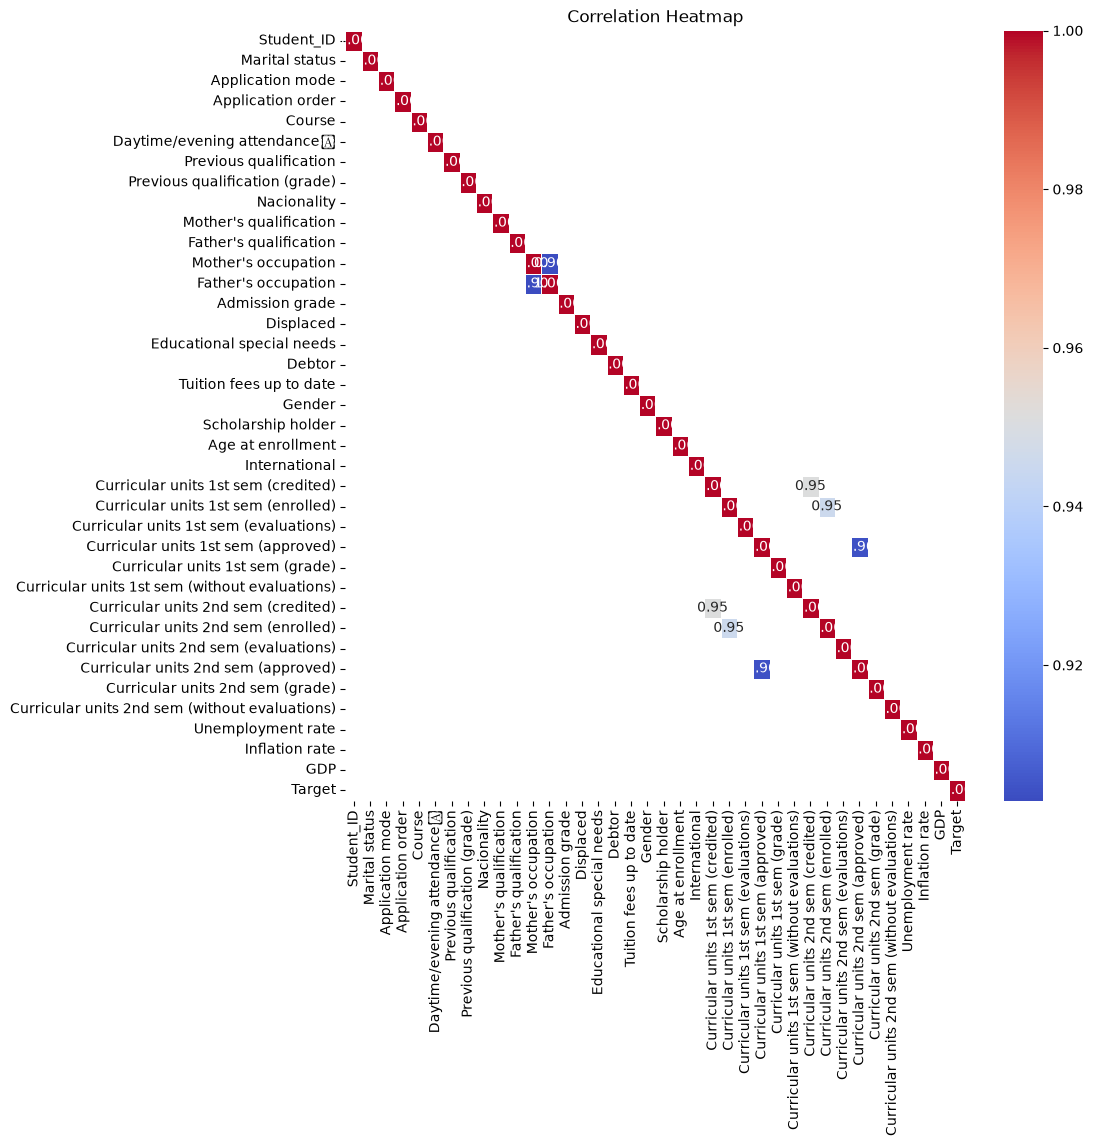

In [24]:
# Pakai data Normalized DF
train_df_features = train_df.corr()
filtered_train_df_features = train_df_features.where(train_df_features>0.9).dropna(how="all", axis=0).dropna(how="all", axis=1)
plt.figure(figsize=(10,10))
sns.heatmap(filtered_train_df_features, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [25]:
train_df.columns

Index(['Student_ID', 'Marital status', 'Application mode', 'Application order',
       'Course', 'Daytime/evening attendance\t', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curric

In [26]:
train_df = train_df.drop(columns=['Student_ID','Marital status','Nacionality',"Mother's qualification", "Father's qualification","Mother's occupation", "Father's occupation","Displaced","Educational special needs", "Gender",'Age at enrollment', 'International'])
test_df = test_df.drop(columns=['Marital status','Nacionality',"Mother's qualification", "Father's qualification","Mother's occupation", "Father's occupation","Displaced","Educational special needs", "Gender",'Age at enrollment', 'International'])

In [27]:
train_df.columns

Index(['Application mode', 'Application order', 'Course',
       'Daytime/evening attendance\t', 'Previous qualification',
       'Previous qualification (grade)', 'Admission grade', 'Debtor',
       'Tuition fees up to date', 'Scholarship holder',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd sem (grade)',
       'Curricular units 2nd sem (without evaluations)', 'Unemployment rate',
       'Inflation rate', 'GDP', 'Target'],
      dtype='str')

# Finalize 

In [28]:
from sklearn.model_selection import train_test_split


In [29]:
X = train_df.drop("Target",axis=1)
y = train_df["Target"]
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

In [30]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [31]:
scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_val_scaled = scaler.fit_transform(X_val)

X_train_scaled = X_train.copy()
X_train_scaled[X_train_scaled.columns] = scaler.fit_transform(X_train[X_train.columns])
X_val_scaled = X_val.copy()
X_val_scaled[X_val_scaled.columns] = scaler.fit_transform(X_val[X_val.columns])


In [32]:
X_train_scaled

,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Admission grade,Debtor,Tuition fees up to date,Scholarship holder,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
302,-1.001238,-0.557817,0.118266,0.338841,-0.356076,1.150926,0.665038,-0.352750,0.369896,-0.585434,...,-0.215555,-0.283696,-0.099033,0.255481,0.516987,0.722844,-0.194475,1.489361,1.159936,-1.798439
1421,-1.001238,-0.557817,0.134349,0.338841,-0.356076,-0.511985,0.231693,-0.352750,0.369896,-0.585434,...,-0.215555,-0.283696,-0.546486,-0.000413,-0.471476,0.339383,-0.194475,-0.284495,0.145043,0.760121
274,1.855816,-0.557817,0.147594,0.338841,1.370943,0.024682,-1.013313,2.834871,-2.703465,-0.585434,...,-0.215555,-0.283696,-0.546486,-0.768096,-1.459940,-1.961380,-0.194475,-1.001586,0.145043,1.540923
258,-0.086981,0.984511,0.314572,0.338841,-0.356076,-0.058464,0.272964,-0.352750,0.369896,-0.585434,...,-0.215555,-0.283696,0.795875,-0.000413,0.846475,0.661764,-0.194475,-0.284495,0.145043,0.760121
484,1.455829,-0.557817,0.079478,0.338841,3.289853,2.057968,2.281482,-0.352750,0.369896,-0.585434,...,-0.215555,-0.283696,-0.099033,0.255481,0.516987,0.476334,-0.194475,0.319371,-0.507388,0.782177
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2154,-1.001238,-0.557817,-4.098299,0.338841,-0.356076,0.243884,1.765596,-0.352750,0.369896,-0.585434,...,-0.215555,-0.283696,-2.783755,-2.047567,-1.459940,-1.961380,-0.194475,0.885495,-1.087326,0.341046
3021,-0.086981,2.526838,0.443709,0.338841,-0.356076,0.092710,-0.346100,-0.352750,0.369896,-0.585434,...,-0.215555,-0.283696,-0.099033,-0.000413,0.516987,0.421553,-0.194475,1.753552,-0.652372,-0.413288
2027,-0.086981,-0.557817,0.198208,0.338841,-0.356076,0.546231,0.211058,-0.352750,0.369896,1.708134,...,-0.215555,-0.283696,-0.099033,0.255481,-0.471476,0.467204,-0.194475,-0.812878,-1.449788,-1.383776
1006,1.398688,-0.557817,0.314572,0.338841,-0.356076,0.546231,0.809486,-0.352750,0.369896,1.708134,...,-0.215555,-0.283696,0.795875,0.767269,1.175963,0.543315,-0.194475,1.753552,-0.652372,-0.413288


In [33]:
X_val_scaled


,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Admission grade,Debtor,Tuition fees up to date,Scholarship holder,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
1183,-0.972255,-0.545903,0.203448,0.362473,-0.343827,0.570952,0.966160,-0.348077,0.359619,1.770122,...,-0.178766,-0.280943,-0.055646,0.460833,-0.111346,0.556473,-0.206603,0.375394,1.777487,-0.733337
175,1.520083,-0.545903,0.123905,0.362473,3.368622,0.570952,0.902451,-0.348077,0.359619,-0.564933,...,-0.178766,0.260003,-0.055646,0.460833,-0.111346,0.280114,-0.206603,0.820696,-1.119383,0.363110
1407,-0.044873,-0.545903,0.447727,0.362473,-0.343827,-0.213149,0.916608,-0.348077,0.359619,1.770122,...,-0.178766,-0.280943,-0.055646,-0.255248,0.562162,0.310821,-0.206603,1.674190,-0.684853,-0.389872
3032,-0.044873,1.024676,0.319233,0.362473,-0.343827,0.257312,0.123777,-0.348077,0.359619,1.770122,...,-0.178766,-0.280943,0.864374,0.460833,1.235670,0.473565,-0.206603,0.264069,-0.540009,0.803451
84,-0.044873,1.024676,-0.380184,-2.758824,-0.343827,-1.389301,-0.867262,-0.348077,-2.780718,-0.564933,...,-0.178766,-0.280943,-0.515657,0.460833,-1.458362,-1.838635,-0.206603,-0.329667,0.111786,0.781434
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
987,1.462121,-0.545903,0.550333,-2.758824,-0.343827,-1.467711,-0.746921,-0.348077,0.359619,-0.564933,...,-0.178766,-0.280943,-0.515657,0.222139,-0.111346,0.298538,1.318327,1.674190,-0.684853,-0.389872
675,-0.044873,-0.545903,-0.380184,-2.758824,-0.343827,-0.605200,-0.357585,2.872931,0.359619,-0.564933,...,-0.178766,-0.280943,-0.055646,-0.255248,0.562162,0.310821,-0.206603,-0.329667,0.111786,0.781434
1417,1.230276,-0.545903,0.550333,-2.758824,-0.343827,-0.997250,1.341339,-0.348077,0.359619,-0.564933,...,-0.178766,-0.280943,-0.515657,0.460833,-0.448100,0.126582,-0.206603,-0.218341,-0.467588,0.904729
1958,1.230276,-0.545903,-0.380184,-2.758824,-0.343827,-0.213149,0.477720,-0.348077,0.359619,1.770122,...,-0.178766,0.260003,0.404364,-0.255248,0.898916,0.740712,-0.206603,-1.034728,0.111786,1.560837


In [34]:
X_train_scaled.to_csv('./data/cleaned/X_train_scaled.csv')
X_val_scaled.to_csv('./data/cleaned/X_val_scaled.csv')
y_train.to_csv('./data/cleaned/y_train.csv')
y_val.to_csv('./data/cleaned/y_val.csv')
test_df.to_csv('./data/cleaned/test_df.csv')